# Link communities of networks

Link clustering puts every edge of a network in one community, so a node belongs to as many
communities as it has kinds of ties. `ac.link_communities` clusters the edges by the similarity
of their endpoints' neighbourhoods, scores every cluster by partition density `D`, and returns
the best single-level cut and the adaptive cut. This is the setting of the paper.

This notebook needs `pip install adaptive_cut networkx matplotlib`.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

import adaptive_cut as ac

## Zachary's karate club

In [2]:
G = nx.karate_club_graph()
r = ac.link_communities(G, rng=0)
print(r)
print(
    f"partition density: single-level {r.level_cut.value:.3f}, adaptive {r.partition_density:.3f}"
)

LinkCommunities(N=34, M=78, balancedness=0.631, D_level=0.2848, D=0.4030, n_communities=29)
partition density: single-level 0.285, adaptive 0.403


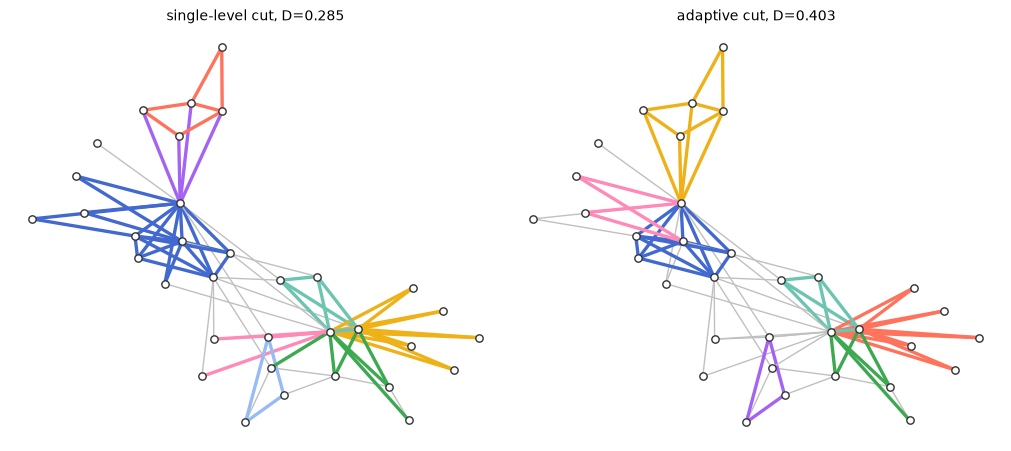

In [3]:
COLORS = [
    "#4269d0",
    "#efb118",
    "#ff725c",
    "#6cc5b0",
    "#3ca951",
    "#ff8ab7",
    "#a463f2",
    "#97bbf5",
    "#9c6b4e",
    "#9498a0",
]
pos = nx.spring_layout(G, seed=1)
xy = np.array([pos[v] for v in r.node_labels])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), layout="constrained")
for ax, cut, title in zip(axes, [r.level_cut, r.cut], ["single-level cut", "adaptive cut"]):
    rank = np.argsort(np.argsort(-cut.sizes))
    for e, (a, b) in enumerate(r.edges):
        k = cut.labels[e]
        big = cut.sizes[k] > 2  # communities of 1-2 edges in grey
        ax.plot(
            *xy[[a, b]].T, color=COLORS[rank[k] % 10] if big else "#c0c0c0", lw=2.4 if big else 1
        )
    ax.scatter(*xy.T, s=28, c="white", edgecolors="#333333", zorder=3)
    ax.set_title(f"{title}, D={cut.value:.3f}", fontsize=10)
    ax.axis("off")

## Communities of each node

Communities are made of edges, so a node belongs to every community one of its edges is in.
`r.memberships()` is a sparse (nodes x communities) matrix with the fraction of each node's
edges in each community. Node 0 (the instructor) spreads over several communities. Notebook 08
lists everything else a result holds.

In [4]:
M = r.memberships().toarray()
node = 0
shares = {int(c): round(float(M[node, c]), 2) for c in np.flatnonzero(M[node])}
print("node 0, share of its edges per community:", shares)

for i, node in enumerate(r.node_labels[:8]):  # communities of the first 8 nodes
    comms = np.flatnonzero(M[i])
    main = comms[np.argmax(M[i, comms])]
    print(f"node {node}: communities {comms.tolist()}, main community {int(main)}")

print("communities of 4+ nodes:", [c.tolist() for c in r.communities() if len(c) >= 4])

node 0, share of its edges per community: {0: 0.31, 1: 0.25, 2: 0.06, 3: 0.06, 4: 0.06, 5: 0.12, 6: 0.06, 7: 0.06}
node 0: communities [0, 1, 2, 3, 4, 5, 6, 7], main community 0
node 1: communities [0, 5, 8, 9], main community 0
node 2: communities [0, 10, 11, 12], main community 0
node 3: communities [0, 13], main community 0
node 4: communities [1], main community 1
node 5: communities [1], main community 1
node 6: communities [1], main community 1
node 7: communities [0], main community 0
communities of 4+ nodes: [[0, 1, 2, 3, 7, 13], [0, 4, 5, 6, 10, 16], [0, 1, 17, 21], [8, 30, 32, 33], [14, 15, 18, 20, 22, 32, 33], [23, 26, 29, 32, 33]]


## Varying density against balanced networks

Two stochastic block models with five blocks. In the first, block densities run from 1 down to
0.1 and sparser blocks are larger; in the second, all blocks are alike. In the varying-density
network no single height of the edge tree suits every block.

In [5]:
def sbm(sizes, P, seed):
    rng = np.random.default_rng(seed)
    block = np.repeat(np.arange(len(sizes)), sizes)
    i, j = np.triu_indices(len(block), 1)
    keep = rng.random(i.size) < np.asarray(P)[block[i], block[j]]
    return np.column_stack([i[keep], j[keep]])


p = np.linspace(1, 0.1, 5)
P = np.diag(p)
for c in range(4):
    P[c, c + 1] = P[c + 1, c] = p[c + 1] ** 2
networks = {
    "varying density": sbm((20 / np.sqrt(p)).astype(int), P, seed=0),
    "balanced": sbm([40] * 5, 0.1 + 0.8 * np.eye(5), seed=0),
}
for name, edges in networks.items():
    r = ac.link_communities(edges, n_steps=50_000, rng=0)
    print(
        f"{name:>16}: B={r.balancedness:.2f}  D single-level={r.level_cut.value:.3f}  "
        f"D adaptive={r.partition_density:.3f}"
    )

 varying density: B=0.26  D single-level=0.422  D adaptive=0.466


        balanced: B=0.66  D single-level=0.618  D adaptive=0.619


## Other inputs

`link_communities` accepts a `networkx.Graph`, an edge array of any sortable labels, or a
symmetric `scipy.sparse` adjacency matrix. Weighted networks: `weighted=True` with a graph or
matrix, or `weights=` with an edge array.

In [6]:
G = nx.les_miserables_graph()
for weighted in [False, True]:
    r = ac.link_communities(G, weighted=weighted, rng=0)
    print(
        f"Les Miserables, weighted={weighted}: D single-level {r.level_cut.value:.3f}, "
        f"adaptive {r.partition_density:.3f}, {r.cut.n_clusters} communities"
    )

Les Miserables, weighted=False: D single-level 0.577, adaptive 0.598, 63 communities
Les Miserables, weighted=True: D single-level 0.506, adaptive 0.506, 46 communities
